# AIS Disabling Events Analysis
This notebook performs exploratory data analysis and data preparation on the AIS disabling events dataset.

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import numpy as np

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)

In [2]:
# Load data
df = pd.read_csv("ais_disabling_events.csv")
gdf = gpd.read_file("eez_v12_lowres.shp")

In [3]:
# 1. Exploratory Data Analysis (EDA)
print("===========HEAD===========")
print(df.head())
print("\n===========INFO===========")
print(df.info())
print("\n===========DESCRIBE===========")
print(df.describe())
print("\n===========ISNULL===========")
print(df.isnull().sum())
print("\n===========NUNIQUE===========")
print(df.nunique())
print("\n===========VALUE COUNTS (FLAG)===========")
print(df["flag"].value_counts())
print(df["gap_hours"].head())

===========HEAD===========
                             gap_id       mmsi vessel_class flag  \
0  40072d9edfca0cfd28872cbf9e382e0c  111112726        other  NaN   
1  52dcbd77bbdad9ee2642f574acf45190  150402949        other  CHN   
2  22b6d49ed4bb4d017884b6299ed185f4  204201370        other  PRT   
3  1abe463d7f61b110c44f1d1b4654a213  204206740        other  PRT   
4  72d047a15e33f67c3c5b91c78ff612be  204209840        other  PRT   

   vessel_length_m  vessel_tonnage_gt        gap_start_timestamp  \
0        32.064056         139.583282  2018-03-22 08:59:22+00:00   
1        54.994278         904.204044  2019-01-31 04:09:19+00:00   
2        15.350000          40.940000  2018-05-27 04:47:20+00:00   
3        20.000000          77.263333  2019-06-21 12:17:01+00:00   
4        20.000000          87.435000  2017-07-02 13:13:08+00:00   

   gap_start_lat  gap_start_lon  gap_start_distance_from_shore_m  \
0      11.847433     -21.832185                         384000.0   
1     -45.895618   

In [4]:
# 2. Data Preparation
print(f"Original shape: {df.shape}")

# Fill null values in the 'flag' column with 'Unknown'
df["flag"] = df["flag"].fillna("Unknown")

df.dropna(inplace=True)

# Save cleaned dataset
df.to_csv("ais_disabling_events_cleaned.csv", index=False)

print(f"Cleaned shape: {df.shape}")
print("\nMissing values after cleaning:")
print(df.isnull().sum())

Original shape: (55368, 15)
Cleaned shape: (55365, 15)

Missing values after cleaning:
gap_id                             0
mmsi                               0
vessel_class                       0
flag                               0
vessel_length_m                    0
vessel_tonnage_gt                  0
gap_start_timestamp                0
gap_start_lat                      0
gap_start_lon                      0
gap_start_distance_from_shore_m    0
gap_end_timestamp                  0
gap_end_lat                        0
gap_end_lon                        0
gap_end_distance_from_shore_m      0
gap_hours                          0
dtype: int64


In [5]:
# 3. Geographic Data Inspection
print(df.columns)
print(f"EEZ CRS: {gdf.crs}")
print(f"EEZ HEAD: {gdf.head()}")
gdf.to_csv("eez_v12_lowres.csv", index=False)
gdf_crs = gdf.crs

Index(['gap_id', 'mmsi', 'vessel_class', 'flag', 'vessel_length_m',
       'vessel_tonnage_gt', 'gap_start_timestamp', 'gap_start_lat',
       'gap_start_lon', 'gap_start_distance_from_shore_m', 'gap_end_timestamp',
       'gap_end_lat', 'gap_end_lon', 'gap_end_distance_from_shore_m',
       'gap_hours'],
      dtype='object')
EEZ CRS: EPSG:4326
EEZ HEAD:    MRGID  \
0   8444   
1   8379   
2   8446   
3   8389   
4   8440   

                                                                     GEONAME  \
0                     United States Exclusive Economic Zone (American Samoa)   
1                                British Exclusive Economic Zone (Ascension)   
2                         New Zealand Exclusive Economic Zone (Cook Islands)   
3  Overlapping claim Falkland / Malvinas Islands: United Kingdom / Argentina   
4                          French Exclusive Economic Zone (French Polynesia)   

   MRGID_TER1           POL_TYPE  MRGID_SOV1                   TERRITORY1  \
0      8670

In [6]:
# Converting the AIS df Long and Lat into a "point" object
ais_gdf = gpd.GeoDataFrame(
    df, # AIS DF
    geometry=gpd.points_from_xy(df['gap_start_lon'], df['gap_start_lat']), # Creating a geometry column converting Lon Lat to Point
    crs="EPSG:4326" # Using the standard GPS system
)

ais_end_gdf = gpd.GeoDataFrame(
    df, # AIS DF
    geometry=gpd.points_from_xy(df['gap_end_lon'], df['gap_end_lat']), # Creating a geometry column converting Lon Lat to Point
    crs="EPSG:4326" # Using the standard GPS system
)

print("===============AIS GDF===============")
print(ais_gdf.head())
print("\n===============AIS END GDF===============")
print(ais_end_gdf.head())

===============AIS GDF===============
                             gap_id       mmsi vessel_class     flag  \
0  40072d9edfca0cfd28872cbf9e382e0c  111112726        other  Unknown   
1  52dcbd77bbdad9ee2642f574acf45190  150402949        other      CHN   
2  22b6d49ed4bb4d017884b6299ed185f4  204201370        other      PRT   
3  1abe463d7f61b110c44f1d1b4654a213  204206740        other      PRT   
4  72d047a15e33f67c3c5b91c78ff612be  204209840        other      PRT   

   vessel_length_m  vessel_tonnage_gt        gap_start_timestamp  \
0        32.064056         139.583282  2018-03-22 08:59:22+00:00   
1        54.994278         904.204044  2019-01-31 04:09:19+00:00   
2        15.350000          40.940000  2018-05-27 04:47:20+00:00   
3        20.000000          77.263333  2019-06-21 12:17:01+00:00   
4        20.000000          87.435000  2017-07-02 13:13:08+00:00   

   gap_start_lat  gap_start_lon  gap_start_distance_from_shore_m  \
0      11.847433     -21.832185                     

In [7]:
# Coordinate transformation and distance calculations
ais_gdf = ais_gdf.to_crs(gdf_crs)
ais_end_gdf = ais_end_gdf.to_crs(gdf_crs)

df["distance_meters"] = ais_gdf.distance(ais_end_gdf)
df["distance_nm"] = df["distance_meters"] / 1852
df["distance_from_shore_shift"] = df["gap_start_distance_from_shore_m"] - df["gap_end_distance_from_shore_m"]

print("Dataset with newly calculated features:")
print(df[['distance_meters', 'distance_nm', 'distance_from_shore_shift']].head())

Dataset with newly calculated features:
   distance_meters  distance_nm  distance_from_shore_shift
0         1.907181     0.001030                        0.0
1         0.087694     0.000047                     4000.0
2         0.121480     0.000066                     8000.0
3         0.115970     0.000063                   -11000.0
4         1.006890     0.000544                    76000.0


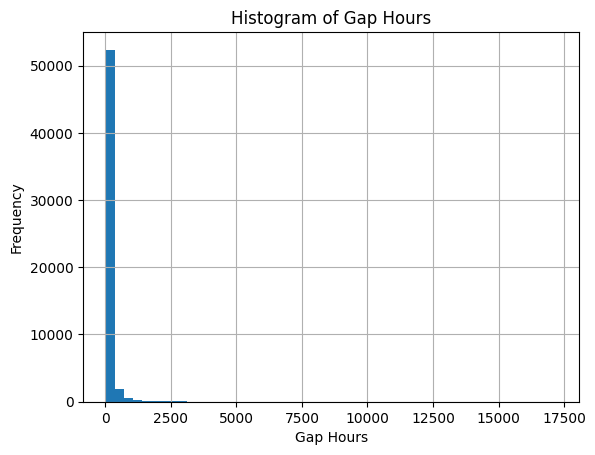

In [8]:
# Generate histogram of gap hours
df["gap_hours"] = df["gap_hours"].astype(float)
df["gap_hours"].hist(bins=50)
plt.title("Histogram of Gap Hours")
plt.xlabel("Gap Hours")
plt.ylabel("Frequency")
plt.show()

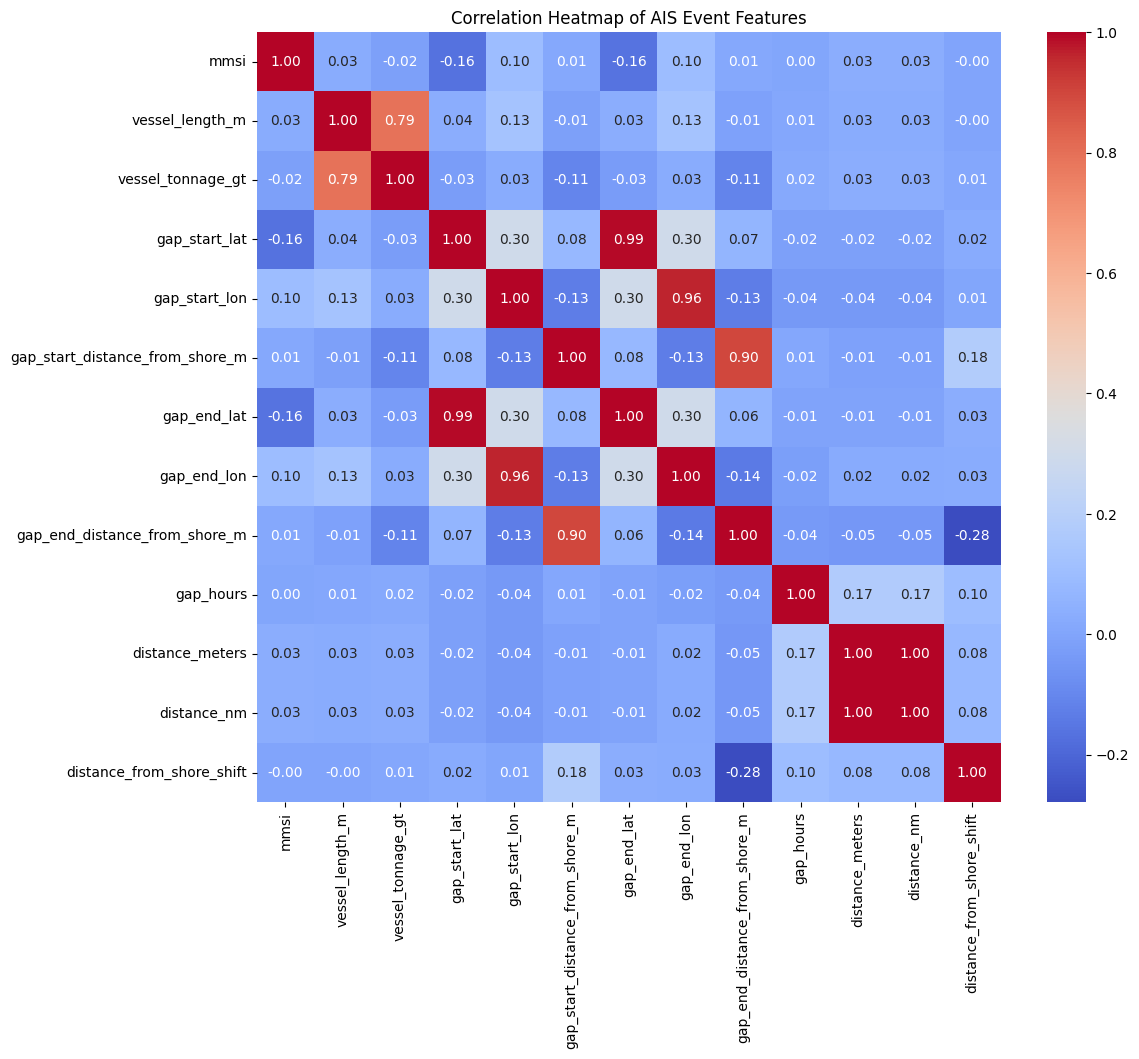

In [9]:
# Plot correlation heatmap
numeric_df = df.select_dtypes(include=['float64', 'int64'])
corr_matrix = numeric_df.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap of AIS Event Features")
plt.show()

In [10]:
from sklearn.linear_model import LinearRegression
X, y = df[["gap_start_distance_from_shore_m"]], df[["gap_end_distance_from_shore_m"]]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42)

X_train
reg = LinearRegression().fit(X_train, y_train)
score = reg.score(X_test, y_test)
print("R2 score = ", score)

R2 score =  0.7939480954810556


Text(0, 0.5, 'Gap End Distance from Shore (m)')

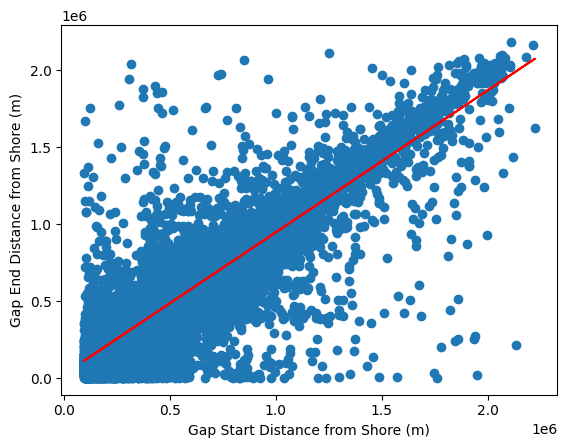

In [11]:
y_pred = reg.predict(X_test)
plt.scatter(X_test, y_test, label="Data")
plt.plot(X_test, y_pred, color='red', label="Line of best fit")

plt.xlabel("Gap Start Distance from Shore (m)")
plt.ylabel("Gap End Distance from Shore (m)")

<Axes: xlabel='gap_start_lat', ylabel='gap_start_lon'>

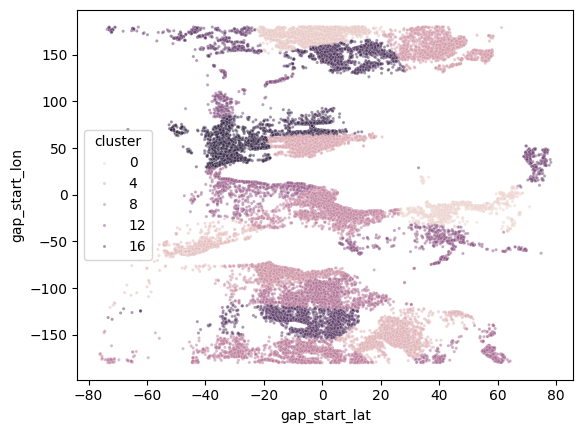

In [12]:
from sklearn.cluster import KMeans

km = KMeans(n_clusters=20)

X_geo = df[["gap_start_lat", "gap_start_lon"]]
X_geo

km.fit(X_geo)
X_geo["cluster"] = km.labels_
X_geo
sns.scatterplot(data=X_geo, x="gap_start_lat", y="gap_start_lon", hue="cluster", s=5, alpha=0.5)


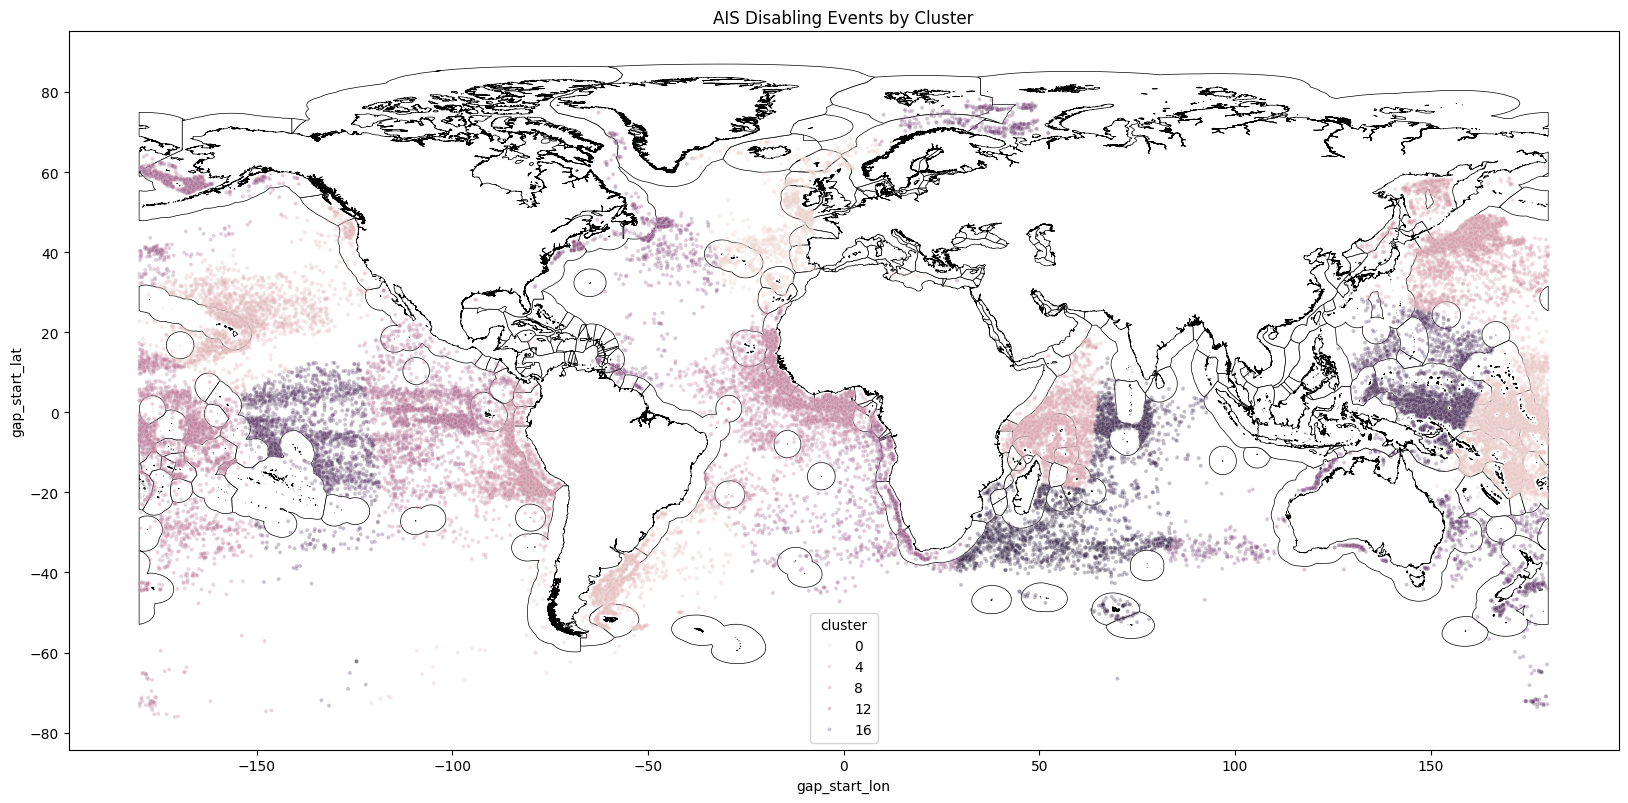

In [13]:
# 1. Create a large canvas for the map
fig, ax = plt.subplots(figsize=(20, 15))

# 2. Plot the EEZ boundaries (the map) on our canvas
gdf.plot(ax=ax, color='white', edgecolor='black', linewidth=0.5)

# 3. Plot your clustered AIS points on top of the same canvas (ax=ax)
sns.scatterplot(
    data=X_geo, 
    x="gap_start_lon", 
    y="gap_start_lat", 
    hue="cluster", 
    s=8, 
    alpha=0.3, 
    ax=ax 
)

plt.title("AIS Disabling Events by Cluster")
plt.show()

In [14]:
df["prolonged"] = (df["gap_hours"] >= 24.0).astype(int)
print(df["prolonged"].value_counts())

prolonged
0    28134
1    27231
Name: count, dtype: int64


Using LabelEncoder to transform columns from categorical to numerical, fit_transform does both steps: learns categories and returns the numbers, each column needs its own LabelEncoder

In [15]:
from sklearn.preprocessing import LabelEncoder
label_encoders = {}
for col in ["flag", "vessel_class"]:
    le = LabelEncoder()
    df[f"{col}_encoded"] = le.fit_transform(df[col])
    label_encoders[col] = le

In [16]:
eez_boundaries = gdf.boundary
print(type(eez_boundaries))
print(eez_boundaries.head(20))
print(eez_boundaries.is_empty.sum())
print(f"Total EEZ boundaries: {len(eez_boundaries)}")

<class 'geopandas.geoseries.GeoSeries'>
0                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                               

In [17]:
projected_crs = "EPSG:3857"
gdf_proj = gdf.to_crs(projected_crs)
ais_gdf_proj = ais_gdf.to_crs(projected_crs)
ais_end_gdf_proj = ais_end_gdf.to_crs(projected_crs)
eez_boundaries_proj = gdf.to_crs(projected_crs).boundary

In [28]:
df["distance_to_eez_start"] = ais_gdf_proj.geometry.apply(
    lambda point: eez_boundaries_proj.distance(point).min()
)

In [19]:
df["distance_to_eez_end"] = ais_end_gdf_proj.geometry.apply(
    lambda point: eez_boundaries_proj.distance(point).min()
)

In [20]:
eez_contains_start = gpd.sjoin(
    ais_gdf_proj, gdf_proj, how="left", predicate="within"
)
eez_contains_end = gpd.sjoin(
    ais_end_gdf_proj, gdf_proj, how="left", predicate="within"
)
eez_contains_start.shape
eez_contains_start.head()

,gap_id,mmsi,vessel_class,flag,vessel_length_m,vessel_tonnage_gt,gap_start_timestamp,gap_start_lat,gap_start_lon,gap_start_distance_from_shore_m,gap_end_timestamp,gap_end_lat,gap_end_lon,gap_end_distance_from_shore_m,gap_hours,geometry,index_right,MRGID,GEONAME,MRGID_TER1,POL_TYPE,MRGID_SOV1,TERRITORY1,ISO_TER1,SOVEREIGN1,MRGID_TER2,MRGID_SOV2,TERRITORY2,ISO_TER2,SOVEREIGN2,MRGID_TER3,MRGID_SOV3,TERRITORY3,ISO_TER3,SOVEREIGN3,X_1,Y_1,MRGID_EEZ,AREA_KM2,ISO_SOV1,ISO_SOV2,ISO_SOV3,UN_SOV1,UN_SOV2,UN_SOV3,UN_TER1,UN_TER2,UN_TER3
0,40072d9edfca0cfd28872cbf9e382e0c,111112726,other,Unknown,32.064056,139.583282,2018-03-22 08:59:22+00:00,11.847433,-21.832185,384000.0,2018-03-22 22:00:56+00:00,11.412485,-23.689107,384000.0,13.016667,POINT (-2430347.717 1328350.231),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,52dcbd77bbdad9ee2642f574acf45190,150402949,other,CHN,54.994278,904.204044,2019-01-31 04:09:19+00:00,-45.895618,-60.642950,396000.0,2019-01-31 18:00:44+00:00,-45.808745,-60.654917,392000.0,13.850000,POINT (-6750742.314 -5763637.734),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,22b6d49ed4bb4d017884b6299ed185f4,204201370,other,PRT,15.350000,40.940000,2018-05-27 04:47:20+00:00,37.836315,-29.405573,95000.0,2018-05-28 14:32:01+00:00,37.860093,-29.286443,87000.0,33.733333,POINT (-3273413.45 4556328.348),61.0,8361.0,Portuguese Exclusive Economic Zone (Azores),2454.0,200NM,2243.0,Azores,None,Portugal,NaN,NaN,None,None,None,NaN,NaN,None,None,None,-27.97601,38.47538,8361.0,960421.0,PRT,None,None,620.0,NaN,NaN,NaN,NaN,NaN
3,1abe463d7f61b110c44f1d1b4654a213,204206740,other,PRT,20.000000,77.263333,2019-06-21 12:17:01+00:00,32.190453,-18.031552,98000.0,2019-06-22 18:56:01+00:00,32.119552,-18.123323,109000.0,30.650000,POINT (-2007263.15 3788336.632),85.0,8363.0,Portuguese Exclusive Economic Zone (Madeira),4956.0,200NM,2243.0,Madeira,None,Portugal,NaN,NaN,None,None,None,NaN,NaN,None,None,None,-16.81091,33.17302,8363.0,452796.0,PRT,None,None,620.0,NaN,NaN,NaN,NaN,NaN
4,72d047a15e33f67c3c5b91c78ff612be,204209840,other,PRT,20.000000,87.435000,2017-07-02 13:13:08+00:00,39.388467,-29.215400,93000.0,2017-07-04 15:30:29+00:00,38.909333,-28.329817,17000.0,50.283333,POINT (-3252243.451 4777469.834),61.0,8361.0,Portuguese Exclusive Economic Zone (Azores),2454.0,200NM,2243.0,Azores,None,Portugal,NaN,NaN,None,None,None,NaN,NaN,None,None,None,-27.97601,38.47538,8361.0,960421.0,PRT,None,None,620.0,NaN,NaN,NaN,NaN,NaN


In [21]:
eez_contains_end = eez_contains_end[~eez_contains_end.index.duplicated(keep='first')]
eez_contains_start = eez_contains_start[~eez_contains_start.index.duplicated(keep='first')]
df["inside_eez_start"] = eez_contains_start["GEONAME"].notna().astype(int)
df["inside_eez_end"] = eez_contains_end["GEONAME"].notna().astype(int)
print(df["inside_eez_start"].value_counts())
print(df["inside_eez_end"].value_counts())


inside_eez_start
0    38228
1    17137
Name: count, dtype: int64
inside_eez_end
0    37660
1    17705
Name: count, dtype: int64


In [32]:
df["eez_distance_shift"] = df["distance_to_eez_start"] - df["distance_to_eez_end"]
sneakers = ((df["inside_eez_start"] == 0) & (df["inside_eez_end"] == 1)).sum()
print(f"Went dark outside, reappeared inside EEZ: {sneakers}")

Went dark outside, reappeared inside EEZ: 2106


In [33]:
feature_cols = [
    "gap_start_lat", "gap_start_lon",
    "gap_end_lat", "gap_end_lon",
    "gap_start_distance_from_shore_m", "gap_end_distance_from_shore_m",
    "distance_meters", "distance_nm", "distance_from_shore_shift",
    "vessel_length_m", "vessel_tonnage_gt",
    "flag_encoded", "vessel_class_encoded",
    "distance_to_eez_start", "distance_to_eez_end", "eez_distance_shift",
    "inside_eez_start", "inside_eez_end"
]

df.head(20)


,gap_id,mmsi,vessel_class,flag,vessel_length_m,vessel_tonnage_gt,gap_start_timestamp,gap_start_lat,gap_start_lon,gap_start_distance_from_shore_m,gap_end_timestamp,gap_end_lat,gap_end_lon,gap_end_distance_from_shore_m,gap_hours,distance_meters,distance_nm,distance_from_shore_shift,prolonged,flag_encoded,vessel_class_encoded,distance_to_eez_end,inside_eez_start,inside_eez_end,distance_to_eez_start,eez_distance_shift
0,40072d9edfca0cfd28872cbf9e382e0c,111112726,other,Unknown,32.064056,139.583282,2018-03-22 08:59:22+00:00,11.847433,-21.832185,384000.0,2018-03-22 22:00:56+00:00,11.412485,-23.689107,384000.0,13.016667,1.907181,0.001030,0.0,0,95,1,11507.280156,0,0,12256.128110,748.847954
1,52dcbd77bbdad9ee2642f574acf45190,150402949,other,CHN,54.994278,904.204044,2019-01-31 04:09:19+00:00,-45.895618,-60.642950,396000.0,2019-01-31 18:00:44+00:00,-45.808745,-60.654917,392000.0,13.850000,0.087694,0.000047,4000.0,0,11,1,8708.114227,0,0,12620.258628,3912.144401
2,22b6d49ed4bb4d017884b6299ed185f4,204201370,other,PRT,15.350000,40.940000,2018-05-27 04:47:20+00:00,37.836315,-29.405573,95000.0,2018-05-28 14:32:01+00:00,37.860093,-29.286443,87000.0,33.733333,0.121480,0.000066,8000.0,1,77,1,110944.585910,1,1,121242.208639,10297.622729
3,1abe463d7f61b110c44f1d1b4654a213,204206740,other,PRT,20.000000,77.263333,2019-06-21 12:17:01+00:00,32.190453,-18.031552,98000.0,2019-06-22 18:56:01+00:00,32.119552,-18.123323,109000.0,30.650000,0.115970,0.000063,-11000.0,1,77,1,129990.902841,1,1,116191.402431,-13799.500411
4,72d047a15e33f67c3c5b91c78ff612be,204209840,other,PRT,20.000000,87.435000,2017-07-02 13:13:08+00:00,39.388467,-29.215400,93000.0,2017-07-04 15:30:29+00:00,38.909333,-28.329817,17000.0,50.283333,1.006890,0.000544,76000.0,1,77,1,21981.146655,1,1,120152.799133,98171.652478
5,87d87366d2def578701b373d1240a958,204225000,other,PRT,25.380000,154.000000,2017-12-10 20:05:37+00:00,38.722653,-30.001233,102000.0,2017-12-11 10:03:05+00:00,38.235638,-29.421588,65000.0,13.950000,0.757081,0.000409,37000.0,0,77,1,83119.060716,1,1,131123.890868,48004.830151
6,48d68185e0b0c35f9a2b04552cfc63d3,204284000,other,PRT,24.000000,147.050000,2018-03-19 01:52:26+00:00,24.779287,-16.362843,109000.0,2018-03-20 00:01:12+00:00,25.209573,-16.202693,130000.0,22.133333,0.459124,0.000248,-21000.0,0,77,1,116536.880971,1,1,121421.865715,4884.984743
7,4fb88a4db1707128bc45295c5a966760,204814000,other,PRT,28.050000,215.000000,2017-08-15 22:20:47+00:00,37.736542,-29.455823,107000.0,2017-08-27 18:59:56+00:00,37.615720,-26.783042,85000.0,284.650000,2.675511,0.001445,22000.0,1,77,1,108964.359370,1,1,135901.900949,26937.541579
8,c2270afe2113ceafb2cd82d7a89cbe56,224000240,other,ESP,33.000000,162.000000,2019-07-05 18:47:46+00:00,31.738387,-17.508000,111000.0,2019-07-10 22:31:30+00:00,32.506525,-18.992483,165000.0,123.716667,1.671445,0.000903,-54000.0,1,24,1,193442.280077,1,1,131449.285074,-61992.995004
9,a1f2565f752ea71ef718453c4cee919f,224006570,other,ESP,28.185000,176.000000,2018-09-21 06:37:43+00:00,52.868560,-12.355587,145000.0,2018-09-21 20:15:43+00:00,52.878315,-12.795858,171000.0,13.633333,0.440380,0.000238,-26000.0,0,24,1,281391.328732,1,1,238729.421377,-42661.907355


In [ ]:
from sklearn.model_selection import train_test_split

X = df[feature_cols]
y = df["prolonged"]
 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42, stratify=y)
print(f"Training: {len(X_train)} samples, {y_train.mean():.2%} prolonged")
print(f"Test:     {len(X_test)} samples, {y_test.mean():.2%} prolonged")

Training: 44292 samples, 49.18% prolonged
Test:     11073 samples, 49.18% prolonged


In [43]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train, y_train)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

In [44]:
from sklearn.metrics import classification_report

y_pred = xgb_model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["Normal", "Prolonged"]))

              precision    recall  f1-score   support

      Normal       0.72      0.82      0.77      5627
   Prolonged       0.79      0.67      0.73      5446

    accuracy                           0.75     11073
   macro avg       0.75      0.75      0.75     11073
weighted avg       0.75      0.75      0.75     11073



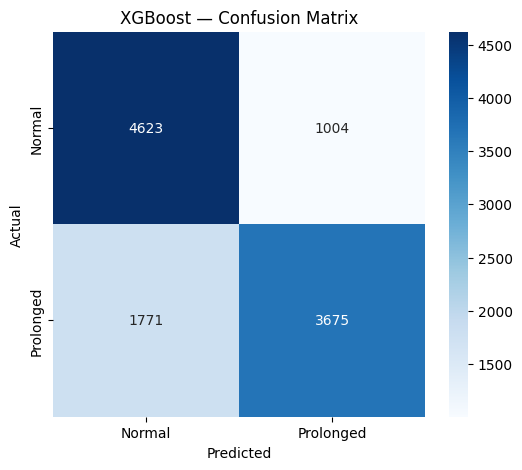

In [45]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Normal", "Prolonged"],
            yticklabels=["Normal", "Prolonged"], ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("XGBoost — Confusion Matrix")
plt.show()

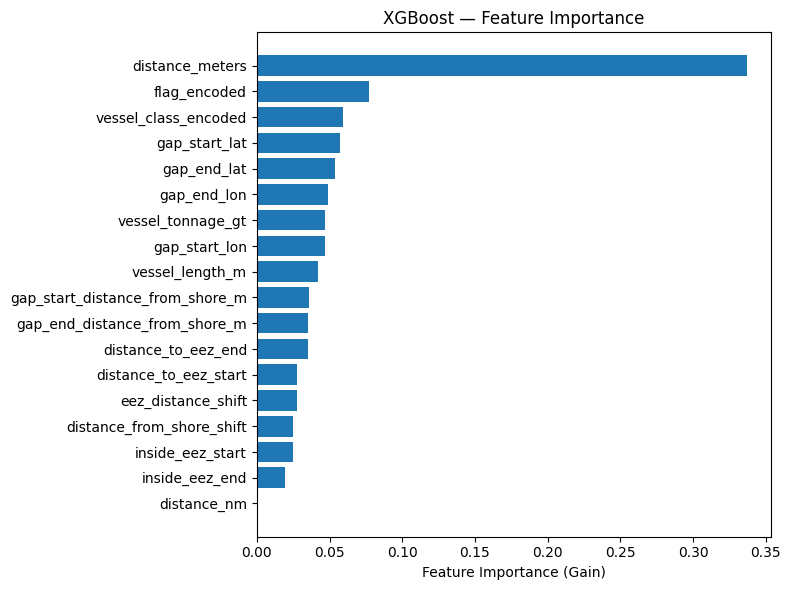

In [46]:
importance = xgb_model.feature_importances_
feat_imp = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": importance
}).sort_values("Importance", ascending=True)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(feat_imp["Feature"], feat_imp["Importance"])
ax.set_xlabel("Feature Importance (Gain)")
ax.set_title("XGBoost — Feature Importance")
plt.tight_layout()
plt.show()